# Lab 2. Windowing in spectral analysis - variant 7

f1 = 400 Hz, f2 = 400.25 Hz, f3 = 399.75 Hz, A1 = 3, A2 = 0.3, A3 = 0.03, fs = 600 Hz, N = 3000

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, fftshift
from scipy.signal.windows import hann, hamming, blackman, flattop

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

f1, f2, f3 = 400, 400.25, 399.75
fs, N = 600, 3000
Amax = 3
A1, A2, A3 = Amax, 0.1*Amax, 0.01*Amax

k = np.arange(N)
x = sum(A*np.sin(2*np.pi*f/fs*k) for A, f in [(A1, f1), (A2, f2), (A3, f3)])

f_alias = {name: fs - f for name, f in [("f1", f1), ("f2", f2), ("f3", f3)]}
print("fs/2 =", fs/2, "Hz, df =", fs/N, "Hz")
print("aliased frequencies:", f_alias)
print("max |x| =", np.abs(x).max())

fs/2 = 300.0 Hz, df = 0.2 Hz
aliased frequencies: {'f1': 200, 'f2': 199.75, 'f3': 200.25}
max |x| = 2.9141456205227265


## Windows (periodic, `sym=False`)

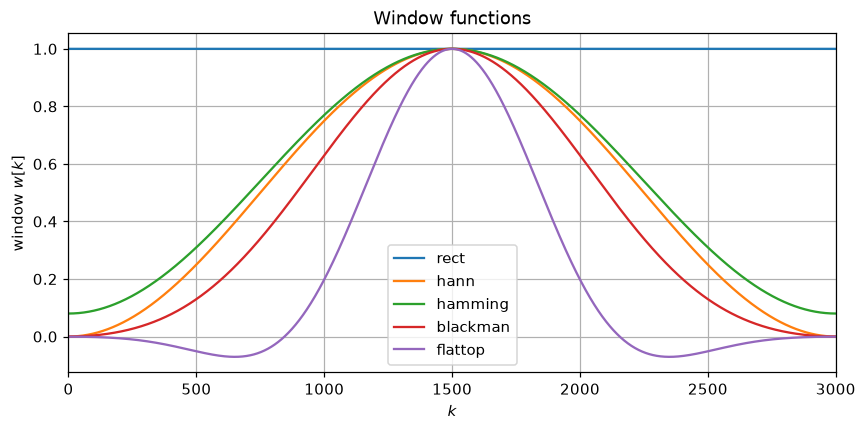

In [2]:
windows = {
    "rect":     np.ones(N),
    "hann":     hann(N, sym=False),
    "hamming":  hamming(N, sym=False),
    "blackman": blackman(N, sym=False),
    "flattop":  flattop(N, sym=False),
}
colors = {n: f"C{i}" for i, n in enumerate(windows)}

plt.figure(figsize=(9, 4))
for n, w in windows.items():
    plt.plot(w, color=colors[n], label=n)
plt.xlabel(r"$k$"); plt.ylabel(r"window $w[k]$"); plt.xlim(0, N); plt.legend()
plt.title("Window functions")
plt.savefig("fig_windows.png", bbox_inches="tight")
plt.show()

## DFT spectra of the windowed signal

{'A1': np.float64(9.54), 'A2': np.float64(-10.46), 'A3': np.float64(-30.46)}


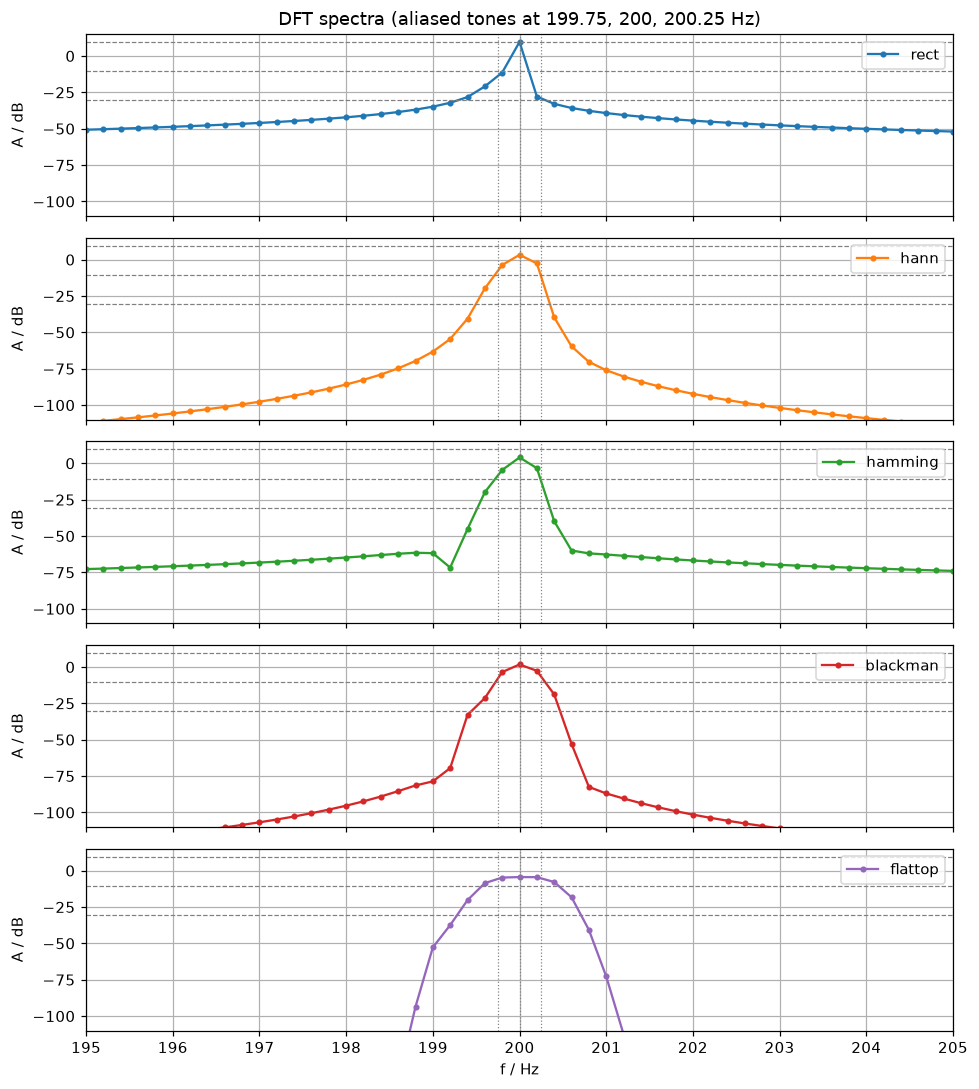

In [3]:
def fft2db(X):
    N = X.size
    Xtmp = 2/N * X
    Xtmp[0] *= 1/2
    if N % 2 == 0:
        Xtmp[N//2] = Xtmp[N//2] / 2
    return 20*np.log10(np.maximum(np.abs(Xtmp), 1e-12))

df = fs/N
f = np.arange(N)*df
half = N//2 + 1
spectra = {n: fft2db(fft(x*w)) for n, w in windows.items()}

levels = {"A1": 20*np.log10(A1), "A2": 20*np.log10(A2), "A3": 20*np.log10(A3)}
print({k_: round(v, 2) for k_, v in levels.items()})

def plot_spectra(xlim, ylim, fname, xticks):
    fig, axs = plt.subplots(len(windows), 1, figsize=(9, 10), sharex=True)
    for ax, (n, S) in zip(axs, spectra.items()):
        ax.plot(f[:half], S[:half], f"{colors[n]}o-", ms=3, label=n)
        for lv in levels.values():
            ax.axhline(lv, color="gray", ls="--", lw=0.8)
        for fa in f_alias.values():
            ax.axvline(fa, color="gray", ls=":", lw=0.8)
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xticks(xticks)
        ax.set_ylabel("A / dB"); ax.legend(loc="upper right")
    axs[-1].set_xlabel("f / Hz")
    axs[0].set_title("DFT spectra (aliased tones at 199.75, 200, 200.25 Hz)")
    fig.tight_layout()
    fig.savefig(fname, bbox_inches="tight")
    plt.show()

plot_spectra((195, 205), (-110, 15), "fig_dft_wide.png", np.arange(195, 206, 1))

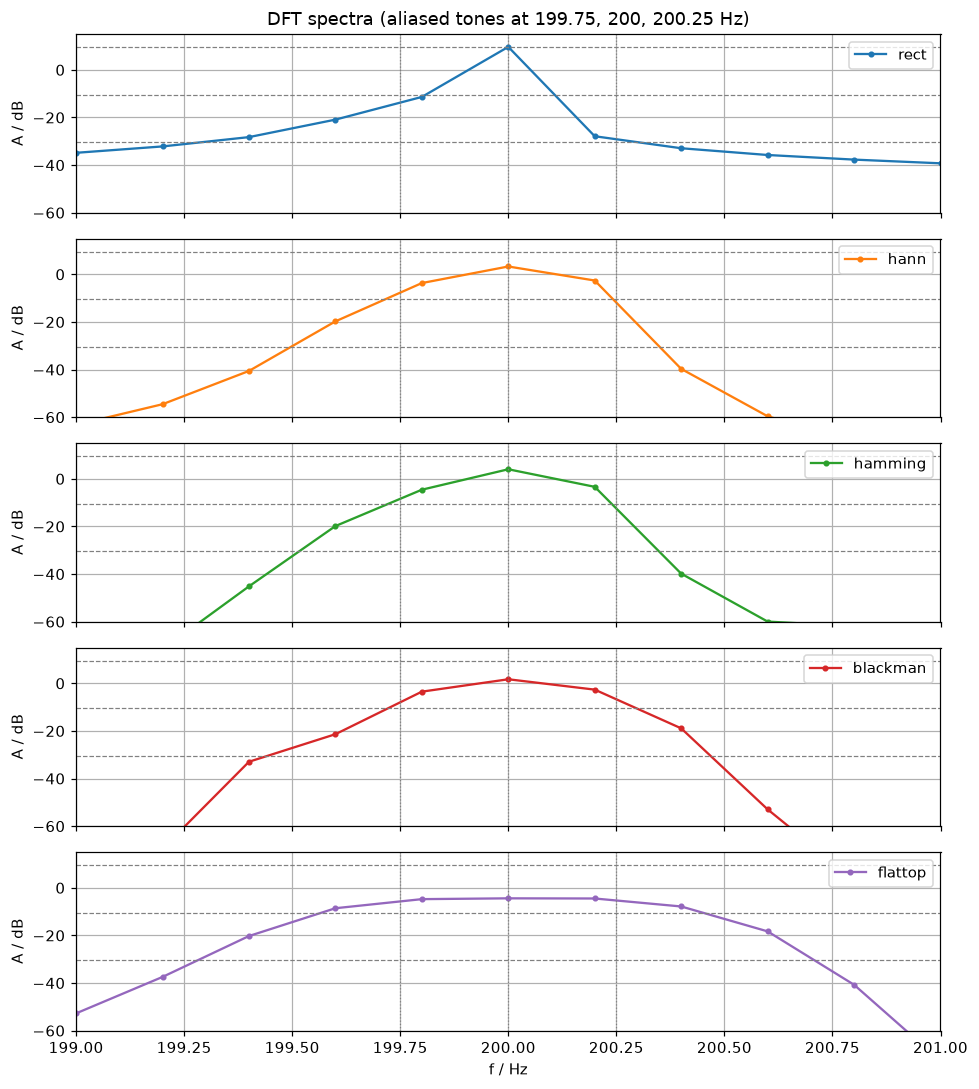

In [4]:
plot_spectra((199, 201), (-60, 15), "fig_dft_zoom.png", np.arange(199, 201.01, 0.25))

## Window DTFT spectra normalised to the mainlobe maximum

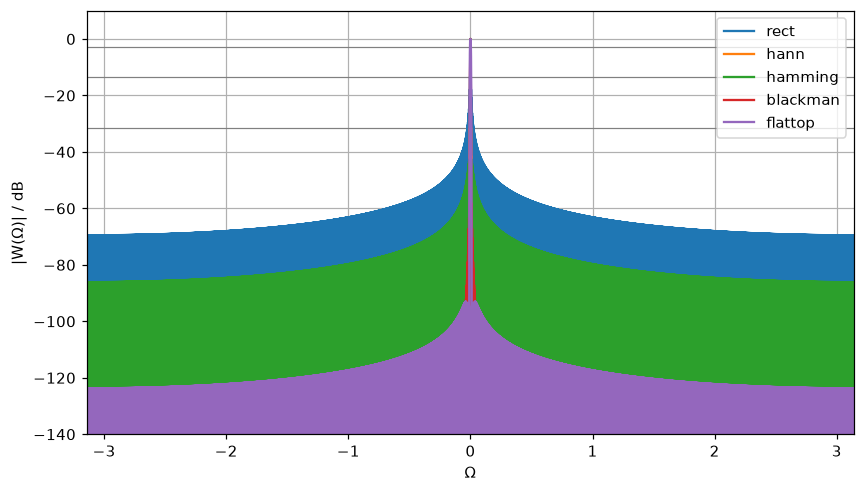

In [5]:
def winDTFTdB(w):
    N = w.size
    Nz = 100*N
    W = np.zeros(Nz)
    W[0:N] = w
    W = np.abs(fftshift(fft(W)))
    W /= np.max(W)
    W = 20*np.log10(np.maximum(W, 1e-12))
    Omega = 2*np.pi/Nz*np.arange(Nz) - np.pi
    return Omega, W

dtft = {n: winDTFTdB(w) for n, w in windows.items()}

def plot_dtft(xlim, fname, ylim=(-140, 10), ref=True):
    plt.figure(figsize=(9, 5))
    if ref:
        for lv in (-3.01, -13.3, -31.5, -93.6):
            plt.plot([-np.pi, np.pi], [lv]*2, "gray", lw=0.8)
    for n, (Om, W) in dtft.items():
        plt.plot(Om, W, color=colors[n], label=n)
    plt.xlim(*xlim); plt.ylim(*ylim)
    plt.xlabel(r"$\Omega$"); plt.ylabel(r"|W($\Omega$)| / dB"); plt.legend()
    plt.savefig(fname, bbox_inches="tight")
    plt.show()

plot_dtft((-np.pi, np.pi), "fig_dtft_full.png")

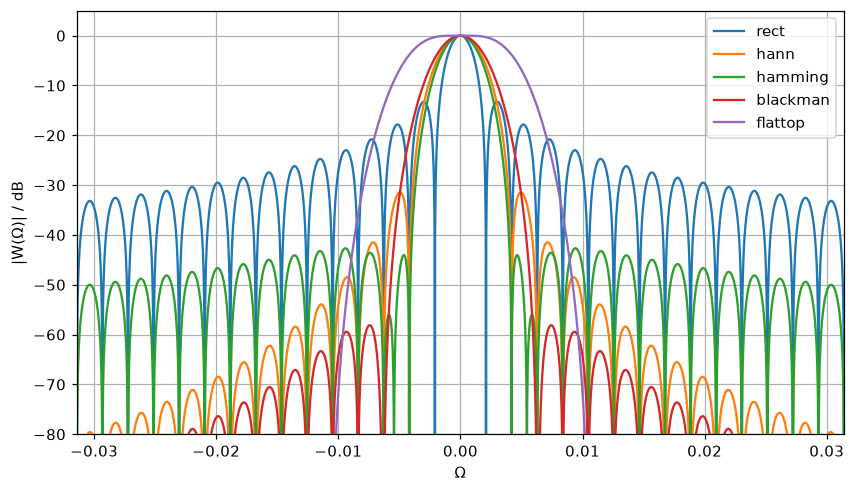

In [6]:
plot_dtft((-np.pi/100, np.pi/100), "fig_dtft_zoom.png", ylim=(-80, 5), ref=False)

## Quantitative comparison

In [7]:
Om, _ = dtft["rect"]
dOm = Om[1] - Om[0]
off = 2*np.pi*(f2 - f1)/fs

def window_metrics(W):
    c = np.argmax(W)
    i = c + np.argmax(W[c:] < -3.01)
    width3 = 2*(i-c)*dOm/(2*np.pi/N)
    while W[i+1] < W[i]:
        i += 1
    return {"mainlobe -3dB width [bins]": width3,
            "mainlobe half-width to 1st null [bins]": (i-c)*dOm/(2*np.pi/N),
            "max sidelobe [dB]": W[i:].max(),
            "mainlobe level at +-0.25 Hz [dB]": W[c + int(round(off/dOm))]}

import pandas as pd
rows = {n: window_metrics(W) for n, (Om_, W) in dtft.items()}
print(pd.DataFrame(rows).T.round(2).to_string())

          mainlobe -3dB width [bins]  mainlobe half-width to 1st null [bins]  max sidelobe [dB]  mainlobe level at +-0.25 Hz [dB]
rect                            0.90                                    1.00             -13.26                            -14.89
hann                            1.46                                    2.00             -31.47                             -9.89
hamming                         1.32                                    2.00             -42.68                            -12.18
blackman                        1.66                                    3.00             -58.11                             -7.18
flattop                         3.20                                    4.73             -93.03                             -1.48


In [8]:
from scipy.signal import find_peaks
Nz = 16*N
fz = np.arange(Nz)*fs/Nz
sel = (fz > 199) & (fz < 201)
print("true tones: 199.75 Hz -> %.1f dB, 200.00 Hz -> %.1f dB, 200.25 Hz -> %.1f dB\n" % (levels['A2'], levels['A1'], levels['A3']))
for n, w in windows.items():
    S = fft2db(fft(x*w, Nz)) + 20*np.log10(Nz/N)
    pk, _ = find_peaks(S[sel], prominence=1)
    print(f"{n:9s} peaks:", ", ".join(f"{fz[sel][p]:.2f} Hz / {S[sel][p]:.1f} dB" for p in pk))

true tones: 199.75 Hz -> -10.5 dB, 200.00 Hz -> 9.5 dB, 200.25 Hz -> -30.5 dB

rect      peaks: 199.10 Hz / -12.9 dB, 199.30 Hz / -10.6 dB, 199.50 Hz / -7.5 dB, 199.71 Hz / -1.2 dB, 200.00 Hz / 9.7 dB, 200.29 Hz / -3.2 dB, 200.49 Hz / -7.9 dB, 200.69 Hz / -10.8 dB, 200.89 Hz / -13.0 dB
hann      peaks: 199.10 Hz / -44.0 dB, 199.31 Hz / -36.4 dB, 199.57 Hz / -19.3 dB, 200.01 Hz / 3.3 dB, 200.46 Hz / -26.9 dB, 200.69 Hz / -37.6 dB, 200.89 Hz / -44.6 dB
hamming   peaks: 199.10 Hz / -38.1 dB, 199.29 Hz / -39.9 dB, 200.00 Hz / 4.0 dB, 200.44 Hz / -35.9 dB, 200.70 Hz / -39.0 dB, 200.90 Hz / -38.0 dB
blackman  peaks: 199.10 Hz / -57.1 dB, 200.01 Hz / 1.7 dB, 200.71 Hz / -57.4 dB, 200.89 Hz / -57.1 dB
flattop   peaks: 200.12 Hz / -4.3 dB
